# Comparative Analysis of LSTM and LightGBM for Bitcoin Price Forecasting

## 1. Objective

This notebook evaluates two machine-learning approaches for next-day Bitcoin closing-price forecasting: Long Short-Term Memory (LSTM) and LightGBM.

The models are compared against a persistence baseline, which predicts the next day's closing price as the current day's closing price.

The analysis covers:

- Overall forecasting performance using MAE, RMSE, MAPE, and R².
- Actual versus predicted closing prices.
- Model performance under low- and high-volatility market conditions.
- A comparison of the machine-learning models against the persistence baseline.

The dataset is divided chronologically into training, validation, and test sets. The test set is reserved for final evaluation.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

DATA_PATH = Path("../data/processed")
RESULTS_PATH = Path("../results")

train_df = pd.read_csv(DATA_PATH / "train.csv")
test_df = pd.read_csv(DATA_PATH / "test.csv")

lstm_df = pd.read_csv(RESULTS_PATH / "lstm_predictions.csv")
lgbm_df = pd.read_csv(RESULTS_PATH / "lightgbm_predictions.csv")

for df in [train_df, test_df, lstm_df, lgbm_df]:
    df["Date"] = pd.to_datetime(df["Date"])

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("LSTM predictions:", len(lstm_df))
print("LightGBM predictions:", len(lgbm_df))

Training rows: 2107
Test rows: 452
LSTM predictions: 452
LightGBM predictions: 452


In [11]:
comparison_df = lstm_df[
    ["Date", "Actual_Close", "LSTM_Prediction"]
].merge(
    lgbm_df[["Date", "LightGBM_Prediction"]],
    on="Date",
    how="inner",
    validate="one_to_one"
)

comparison_df = comparison_df.merge(
    test_df[["Date", "Close", "Target", "Volatility_7"]],
    on="Date",
    how="inner",
    validate="one_to_one"
)

comparison_df = comparison_df.sort_values("Date").reset_index(drop=True)

# Confirm the saved actual values agree with the test targets
assert np.allclose(
    comparison_df["Actual_Close"],
    comparison_df["Target"]
), "Actual target values do not match."

# Persistence: tomorrow's price = today's closing price
comparison_df["Persistence_Prediction"] = comparison_df["Close"]

print("Aligned observations:", len(comparison_df))
print("Dates:", comparison_df["Date"].min(), "to",
      comparison_df["Date"].max())

display(comparison_df.head())

Aligned observations: 452
Dates: 2021-01-08 00:00:00 to 2022-10-16 00:00:00


,Date,Actual_Close,LSTM_Prediction,LightGBM_Prediction,Close,Target,Volatility_7,Persistence_Prediction
0,2021-01-08,40254.546498,40930.689417,40648.665561,40797.610720,40254.546498,0.060298,40797.610720
1,2021-01-09,38356.439507,40386.084099,40114.701115,40254.546498,38356.439507,0.063795,40254.546498
2,2021-01-10,35566.655940,38482.725835,38121.230899,38356.439507,35566.655940,0.068867,38356.439507
3,2021-01-11,37316.359400,35685.325824,35348.554789,35566.655940,37316.359400,0.078765,35566.655940
4,2021-01-13,39187.328121,37440.889497,37636.867572,37316.359400,39187.328121,0.077617,37316.359400


In [12]:
def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100,
        "R2": r2_score(actual, predicted)
    }

actual = comparison_df["Actual_Close"]

metrics_df = pd.DataFrame({
    "LSTM": calculate_metrics(
        actual, comparison_df["LSTM_Prediction"]
    ),
    "LightGBM": calculate_metrics(
        actual, comparison_df["LightGBM_Prediction"]
    ),
    "Persistence": calculate_metrics(
        actual, comparison_df["Persistence_Prediction"]
    )
}).T

display(metrics_df.round(4))

metrics_df.to_csv(
    RESULTS_PATH / "overall_model_comparison.csv"
)

,MAE,RMSE,MAPE (%),R2
LSTM,1427.6039,1940.6696,3.4074,0.9705
LightGBM,1444.1175,1943.8558,3.4529,0.9704
Persistence,1420.7692,1931.2459,3.3894,0.9708


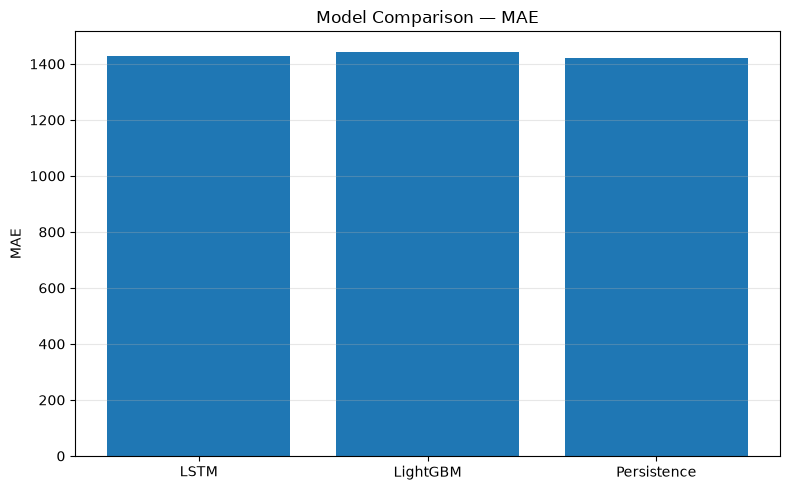

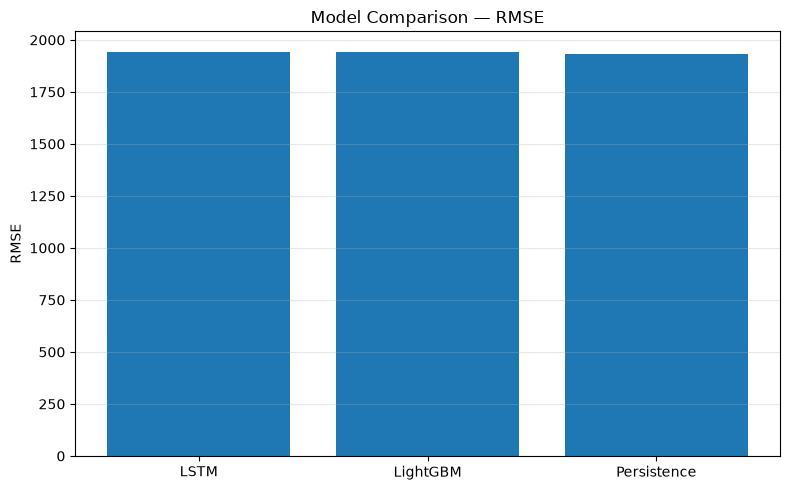

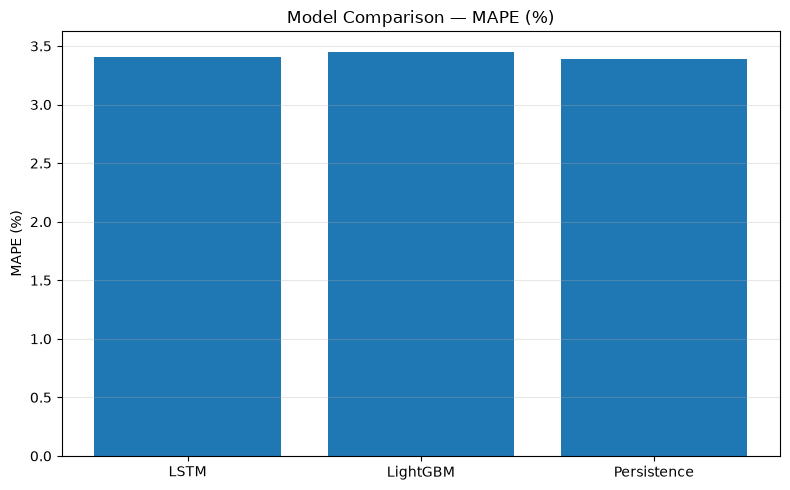

In [13]:
for metric in ["MAE", "RMSE", "MAPE (%)"]:
    plt.figure(figsize=(8, 5))

    plt.bar(metrics_df.index, metrics_df[metric])

    plt.title(f"Model Comparison — {metric}")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        RESULTS_PATH / f"comparison_{metric.replace(' ', '_').replace('(', '').replace(')', '')}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

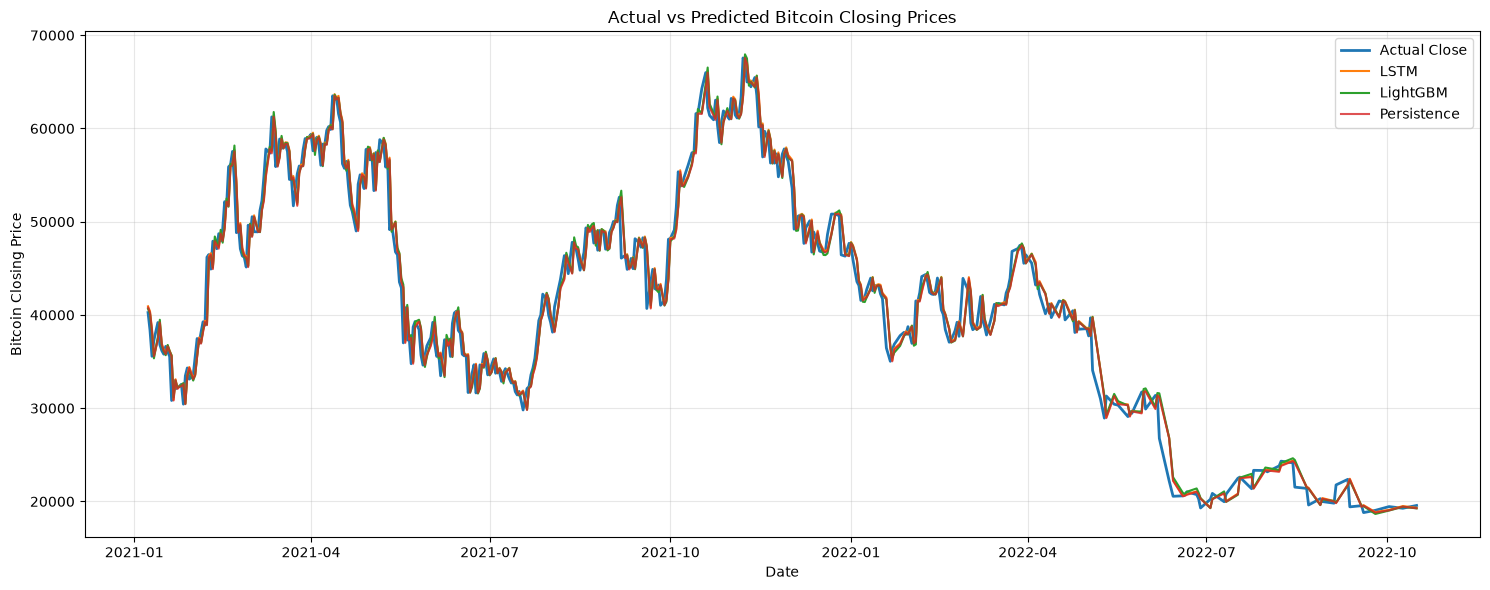

In [14]:
plt.figure(figsize=(15, 6))

plt.plot(
    comparison_df["Date"],
    comparison_df["Actual_Close"],
    label="Actual Close",
    linewidth=2
)

plt.plot(
    comparison_df["Date"],
    comparison_df["LSTM_Prediction"],
    label="LSTM"
)

plt.plot(
    comparison_df["Date"],
    comparison_df["LightGBM_Prediction"],
    label="LightGBM"
)

plt.plot(
    comparison_df["Date"],
    comparison_df["Persistence_Prediction"],
    label="Persistence",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Bitcoin Closing Price")
plt.title("Actual vs Predicted Bitcoin Closing Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "actual_vs_predicted_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
volatility_threshold = train_df["Volatility_7"].median()

comparison_df["Market_Regime"] = np.where(
    comparison_df["Volatility_7"] > volatility_threshold,
    "High Volatility",
    "Low Volatility"
)

print("Training volatility threshold:", volatility_threshold)
print("\nTest observations by regime:")
print(comparison_df["Market_Regime"].value_counts())

display(
    comparison_df[
        ["Date", "Volatility_7", "Market_Regime"]
    ].head()
)

Training volatility threshold: 0.0271815584472859

Test observations by regime:
Market_Regime
High Volatility    381
Low Volatility      71
Name: count, dtype: int64


,Date,Volatility_7,Market_Regime
0,2021-01-08,0.060298,High Volatility
1,2021-01-09,0.063795,High Volatility
2,2021-01-10,0.068867,High Volatility
3,2021-01-11,0.078765,High Volatility
4,2021-01-13,0.077617,High Volatility


In [16]:
regime_results = []

for regime in ["Low Volatility", "High Volatility"]:
    subset = comparison_df[
        comparison_df["Market_Regime"] == regime
    ]

    actual_regime = subset["Actual_Close"]

    for model_name, prediction_column in [
        ("LSTM", "LSTM_Prediction"),
        ("LightGBM", "LightGBM_Prediction"),
        ("Persistence", "Persistence_Prediction")
    ]:
        predicted = subset[prediction_column]

        regime_results.append({
            "Regime": regime,
            "Model": model_name,
            "Observations": len(subset),
            "MAE": mean_absolute_error(
                actual_regime, predicted
            ),
            "RMSE": np.sqrt(mean_squared_error(
                actual_regime, predicted
            )),
            "MAPE (%)": np.mean(
                np.abs(
                    (actual_regime - predicted) / actual_regime
                )
            ) * 100
        })

regime_df = pd.DataFrame(regime_results)

display(regime_df.round(4))

regime_df.to_csv(
    RESULTS_PATH / "volatility_regime_comparison.csv",
    index=False
)

,Regime,Model,Observations,MAE,RMSE,MAPE (%)
0,Low Volatility,LSTM,71,1509.4256,2102.6554,3.2061
1,Low Volatility,LightGBM,71,1529.1722,2115.0633,3.2532
2,Low Volatility,Persistence,71,1525.1848,2097.6674,3.2300
3,High Volatility,LSTM,381,1412.3562,1908.9645,3.4449
4,High Volatility,LightGBM,381,1428.2674,1910.2556,3.4902
5,High Volatility,Persistence,381,1401.3112,1898.6211,3.4191


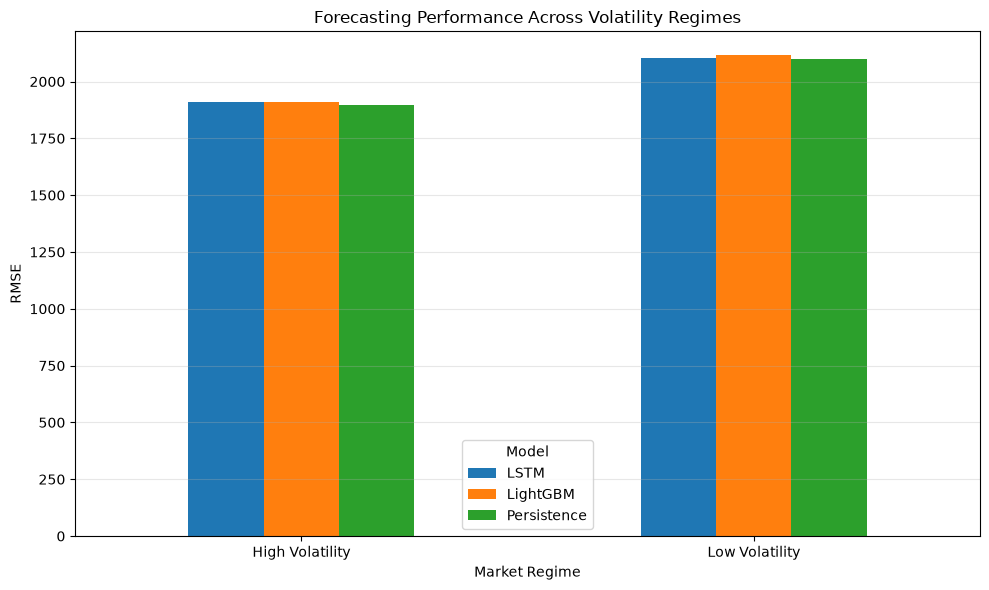

In [17]:
regime_pivot = regime_df.pivot(
    index="Regime",
    columns="Model",
    values="RMSE"
)

regime_pivot = regime_pivot[
    ["LSTM", "LightGBM", "Persistence"]
]

ax = regime_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Forecasting Performance Across Volatility Regimes")
ax.set_xlabel("Market Regime")
ax.set_ylabel("RMSE")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    RESULTS_PATH / "volatility_regime_rmse.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [18]:
print("Best overall model by metric:")
print("Lowest MAE:", metrics_df["MAE"].idxmin())
print("Lowest RMSE:", metrics_df["RMSE"].idxmin())
print("Lowest MAPE:", metrics_df["MAPE (%)"].idxmin())
print("Highest R2:", metrics_df["R2"].idxmax())

print("\nBest model by regime and RMSE:")
for regime in ["Low Volatility", "High Volatility"]:
    subset = regime_df[regime_df["Regime"] == regime]
    best_model = subset.loc[subset["RMSE"].idxmin(), "Model"]
    print(regime + ":", best_model)

Best overall model by metric:
Lowest MAE: Persistence
Lowest RMSE: Persistence
Lowest MAPE: Persistence
Highest R2: Persistence

Best model by regime and RMSE:
Low Volatility: Persistence
High Volatility: Persistence


In [19]:
comparison_df.to_csv(
    RESULTS_PATH / "combined_predictions.csv",
    index=False
)

metrics_df.to_csv(
    RESULTS_PATH / "overall_model_comparison.csv"
)

print("Final comparison outputs saved in:", RESULTS_PATH.resolve())

Final comparison outputs saved in: C:\Crypto_Forecasting_Project\LSTM_Light_GBM\results


## 2. Evaluation Metrics

The models are evaluated using four standard regression metrics.

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted closing prices.
- **Root Mean Squared Error (RMSE):** Penalizes larger prediction errors more strongly than MAE.
- **Mean Absolute Percentage Error (MAPE):** Expresses the average absolute prediction error as a percentage of the actual closing price.
- **Coefficient of Determination (R²):** Measures predictive performance relative to a constant-mean reference.

Lower MAE, RMSE, and MAPE values indicate lower prediction errors. Higher R² indicates better performance relative to the mean-target reference. These metrics are considered together because no single metric fully describes forecasting quality.

## 5. Results and Discussion: Volatility-Regime Analysis

The test observations were classified into low- and high-volatility regimes using a threshold calculated from the training dataset. Applying this fixed threshold produced 71 low-volatility observations and 381 high-volatility observations.

In the low-volatility regime, LSTM achieved an MAE of 1,509.43 and an RMSE of 2,102.66, outperforming LightGBM on both metrics. The persistence baseline achieved an RMSE of 2,097.67, which was marginally lower than that of both machine-learning models.

In the high-volatility regime, LSTM achieved an MAE of 1,412.36 and an RMSE of 1,908.96, while LightGBM achieved an MAE of 1,428.27 and an RMSE of 1,910.26. The persistence baseline achieved the lowest RMSE of 1,898.62 and the lowest MAE of 1,401.31.

These results indicate that LSTM performs better than LightGBM across both volatility regimes in terms of the reported error metrics. However, the persistence baseline remains competitive and achieves lower RMSE in both regimes. Therefore, the analysis does not establish that the machine-learning models consistently outperform a simple forecasting method.

The regime groups contain different numbers of observations, with the high-volatility regime accounting for most of the test period. This imbalance, together with the limited historical evaluation window, should be considered when interpreting the results. Further evaluation across multiple chronological test windows would help determine whether these performance patterns persist under different market conditions.

## 6. Statistical Significance Analysis

The overall performance metrics indicate relatively small differences between LSTM, LightGBM, and the persistence baseline. To investigate whether these differences are robust, a paired moving-block bootstrap is applied to the test-period prediction errors.

For each pair of models, the absolute error difference is calculated for every test observation:

\[
d_t = |e_{A,t}| - |e_{B,t}|
\]

where \(e_{A,t}\) and \(e_{B,t}\) denote the prediction errors of models A and B on the same observation.

A negative mean difference indicates that model A has lower mean absolute error than model B. A positive difference indicates that model B has lower mean absolute error.

Contiguous blocks of observations are resampled to preserve some of the temporal dependence in the error sequence. A 95% bootstrap confidence interval is then calculated for the mean paired difference. If this interval excludes zero, the difference is inconsistent with zero at the corresponding bootstrap confidence level, subject to the assumptions and limitations of the resampling procedure.

This analysis assesses uncertainty in the difference in mean absolute error. It does not establish that a model is universally superior or that the same result will hold in future market conditions.

In [20]:
models = {
    "LSTM": "LSTM_Prediction",
    "LightGBM": "LightGBM_Prediction",
    "Persistence": "Persistence_Prediction"
}

# Sort observations chronologically
comparison_df = comparison_df.sort_values("Date").reset_index(drop=True)

actual = comparison_df["Actual_Close"].to_numpy()

# Calculate absolute errors
for model_name, prediction_column in models.items():
    comparison_df[f"{model_name}_AbsError"] = np.abs(
        actual - comparison_df[prediction_column].to_numpy()
    )

display(
    comparison_df[
        ["Date", "LSTM_AbsError", "LightGBM_AbsError", "Persistence_AbsError"]
    ].head()
)

,Date,LSTM_AbsError,LightGBM_AbsError,Persistence_AbsError
0,2021-01-08,676.142919,394.119063,543.064222
1,2021-01-09,2029.644593,1758.261609,1898.106992
2,2021-01-10,2916.069894,2554.574958,2789.783566
3,2021-01-11,1631.033576,1967.804611,1749.703459
4,2021-01-13,1746.438624,1550.460549,1870.968721


In [21]:
def moving_block_bootstrap(
    differences,
    block_length=7,
    n_bootstrap=5000,
    seed=42
):
    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    n = len(differences)

    if n < block_length:
        raise ValueError("Not enough observations for the selected block length.")

    rng = np.random.default_rng(seed)
    number_of_blocks = int(np.ceil(n / block_length))
    possible_starts = np.arange(n - block_length + 1)

    bootstrap_means = np.empty(n_bootstrap)

    for b in range(n_bootstrap):
        starts = rng.choice(
            possible_starts,
            size=number_of_blocks,
            replace=True
        )

        sample = np.concatenate([
            differences[start:start + block_length]
            for start in starts
        ])[:n]

        bootstrap_means[b] = sample.mean()

    lower, upper = np.percentile(bootstrap_means, [2.5, 97.5])

    return {
        "Mean_Difference": differences.mean(),
        "CI_Lower_95": lower,
        "CI_Upper_95": upper,
        "Bootstrap_Repetitions": n_bootstrap,
        "Block_Length": block_length
    }

In [22]:
comparisons = [
    ("LSTM", "LightGBM"),
    ("LSTM", "Persistence"),
    ("LightGBM", "Persistence")
]

statistical_results = []

for model_a, model_b in comparisons:
    error_a = comparison_df[f"{model_a}_AbsError"].to_numpy()
    error_b = comparison_df[f"{model_b}_AbsError"].to_numpy()

    difference = error_a - error_b

    result = moving_block_bootstrap(
        difference,
        block_length=7,
        n_bootstrap=5000,
        seed=42
    )

    lower = result["CI_Lower_95"]
    upper = result["CI_Upper_95"]

    if upper < 0:
        interpretation = f"{model_a} has lower MAE"
    elif lower > 0:
        interpretation = f"{model_b} has lower MAE"
    else:
        interpretation = "Difference not clearly separated from zero"

    statistical_results.append({
        "Comparison": f"{model_a} - {model_b}",
        **result,
        "Interpretation": interpretation
    })

statistical_df = pd.DataFrame(statistical_results)

display(statistical_df.round(4))

,Comparison,Mean_Difference,CI_Lower_95,CI_Upper_95,Bootstrap_Repetitions,Block_Length,Interpretation
0,LSTM - LightGBM,-16.5136,-35.5698,0.9630,5000,7,Difference not clearly separated from zero
1,LSTM - Persistence,6.8347,-4.0640,17.1123,5000,7,Difference not clearly separated from zero
2,LightGBM - Persistence,23.3483,4.9217,43.5129,5000,7,Persistence has lower MAE


In [23]:
for _, row in statistical_df.iterrows():
    print("\nComparison:", row["Comparison"])
    print(f"Mean MAE difference: {row['Mean_Difference']:.2f}")
    print(
        f"95% bootstrap CI: "
        f"[{row['CI_Lower_95']:.2f}, {row['CI_Upper_95']:.2f}]"
    )
    print("Interpretation:", row["Interpretation"])


Comparison: LSTM - LightGBM
Mean MAE difference: -16.51
95% bootstrap CI: [-35.57, 0.96]
Interpretation: Difference not clearly separated from zero

Comparison: LSTM - Persistence
Mean MAE difference: 6.83
95% bootstrap CI: [-4.06, 17.11]
Interpretation: Difference not clearly separated from zero

Comparison: LightGBM - Persistence
Mean MAE difference: 23.35
95% bootstrap CI: [4.92, 43.51]
Interpretation: Persistence has lower MAE


In [24]:
robustness_results = []

for block_length in [7, 14]:
    for model_a, model_b in comparisons:
        difference = (
            comparison_df[f"{model_a}_AbsError"].to_numpy()
            - comparison_df[f"{model_b}_AbsError"].to_numpy()
        )

        result = moving_block_bootstrap(
            difference,
            block_length=block_length,
            n_bootstrap=5000,
            seed=42
        )

        robustness_results.append({
            "Block_Length": block_length,
            "Comparison": f"{model_a} - {model_b}",
            "Mean_Difference": result["Mean_Difference"],
            "CI_Lower_95": result["CI_Lower_95"],
            "CI_Upper_95": result["CI_Upper_95"],
            "CI_Contains_Zero": (
                result["CI_Lower_95"] <= 0 <= result["CI_Upper_95"]
            )
        })

robustness_df = pd.DataFrame(robustness_results)
display(robustness_df.round(4))

,Block_Length,Comparison,Mean_Difference,CI_Lower_95,CI_Upper_95,CI_Contains_Zero
0,7,LSTM - LightGBM,-16.5136,-35.5698,0.9630,True
1,7,LSTM - Persistence,6.8347,-4.0640,17.1123,True
2,7,LightGBM - Persistence,23.3483,4.9217,43.5129,False
3,14,LSTM - LightGBM,-16.5136,-35.5680,-0.5935,False
4,14,LSTM - Persistence,6.8347,-4.4025,16.4730,True
5,14,LightGBM - Persistence,23.3483,6.0913,44.0609,False


In [25]:
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

statistical_df.to_csv(
    RESULTS_PATH / "statistical_significance_analysis.csv",
    index=False
)

robustness_df.to_csv(
    RESULTS_PATH / "bootstrap_robustness_analysis.csv",
    index=False
)

print("Statistical analysis saved successfully.")

Statistical analysis saved successfully.


## 7. Statistical Significance and Robustness Analysis

A paired moving-block bootstrap was conducted to investigate uncertainty in the differences in mean absolute error (MAE) between LSTM, LightGBM, and the persistence baseline. The analysis used 5,000 bootstrap repetitions, with block lengths of seven and 14 observations.

For the seven-observation block analysis, the mean paired MAE difference between LSTM and LightGBM was −16.51, with a 95% bootstrap confidence interval of [−35.57, 0.96]. Because the interval includes zero, the analysis does not clearly distinguish their MAE.

The mean difference between LSTM and persistence was 6.83, with a 95% confidence interval of [−4.06, 17.11]. This interval also includes zero, providing no clear evidence of a difference in their mean absolute errors.

For LightGBM versus persistence, the mean difference was 23.35, with a 95% confidence interval of [4.92, 43.51]. The interval is entirely positive, indicating higher MAE for LightGBM under this bootstrap analysis.

The sensitivity analysis using 14-observation blocks produced a confidence interval of [−35.57, −0.59] for LSTM versus LightGBM, which excludes zero. The corresponding interval for LSTM versus persistence remained inclusive of zero, while the interval for LightGBM versus persistence remained positive.

The change in the LSTM–LightGBM conclusion across block lengths indicates that the apparent difference is sensitive to the resampling configuration. Therefore, the results do not establish robust statistical superiority of LSTM over LightGBM. The comparison between LightGBM and persistence is more consistent across the two configurations.

These findings are limited to the selected historical test period. The confidence intervals are exploratory, are not adjusted for multiple pairwise comparisons, and depend on the assumptions of the moving-block bootstrap. Further evaluation over multiple chronological test windows would be needed to assess whether the observed differences generalize to other market conditions.